# Практика 3 · сохранённые результаты эксперимента

Этот ноутбук **только читает** завершённый эксперимент и показывает таблицы и карты. Он не запускает сервер, CBC или полный поиск. Подходит для видео и сдачи даже если в интерактивном `full_school_search.ipynb` не сохранены выводы ячеек. Источник — `state/experiment-results/`, подтверждённый полный рейтинг и три сценария.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
assert (ROOT/"state/experiment-results").exists(), "Запустите ноутбук из папки school-placement."
DATA=ROOT/"state/experiment-results"
proof=json.loads((DATA/"experiment-validation.json").read_text(encoding="utf8"))
ranking=pd.read_csv(DATA/"ranking-all-12805.csv",sep=";")
best=pd.read_csv(DATA/"equal-best.csv",sep=";")
comparison=pd.read_csv(DATA/"comparison.csv",sep=";")
assert proof["exhaustive"] and proof["processed"]==12805 and len(ranking)==ranking.id.nunique()==12805
assert ranking.error.isna().all() and len(best)==2877
print("ПОЛНЫЙ ПЕРЕБОР ЗАВЕРШЁН: 12805 / 12805; ошибок 0.")
print("Вместимость новой школы: 600 мест; каждый вариант независим.")
print("Равноценных лучших:",len(best),"максимальное сокращение:",best.reduction.max(),"мест.")
print("А (№ 9345) входит в лучшие:",9345 in set(best.id))
print("В: № 41, минимальный ID среди равных; не единственный оптимум.")
print("Ручное воспроизведение В и сверка всех кварталов с BlocksNet:",proof["manual_reproduction_verified"] and proof["reference_per_block_verified"])
display(comparison.rename(columns={"scenario":"Сценарий","capacity":"Вместимость","added":"Добавлено","deficit":"Дефицит","reduction":"Сокращение","demand":"Потребность","improved_blocks":"Улучшено кварталов","worsened_blocks":"Ухудшено кварталов"}))

ПОЛНЫЙ ПЕРЕБОР ЗАВЕРШЁН: 12805 / 12805; ошибок 0.
Вместимость новой школы: 600 мест; каждый вариант независим.
Равноценных лучших: 2877 максимальное сокращение: 600.0 мест.
А (№ 9345) входит в лучшие: True
В: № 41, минимальный ID среди равных; не единственный оптимум.
Ручное воспроизведение В и сверка всех кварталов с BlocksNet: True


,Сценарий,Вместимость,Добавлено,Дефицит,Сокращение,Потребность,Улучшено кварталов,Ухудшено кварталов
0,Исходное состояние,106942.0,0.0,54209.0,0.0,146028.0,0,0
1,А,107542.0,600.0,53609.0,600.0,146028.0,1,0
2,Б,107542.0,600.0,53609.0,600.0,146028.0,2,0
3,В,107542.0,600.0,53609.0,600.0,146028.0,5,0


## География изменений

У всех трёх итоговый дефицит 53 609 вместо 54 209; сокращение 600 мест, или около 1,11%. А улучшает 1 квартал, Б — 2, В — 5. В № 41 только 2 новых места покрывают собственную потребность, 598 — потребности соседей. Выбор участка строительства не выполнялся.

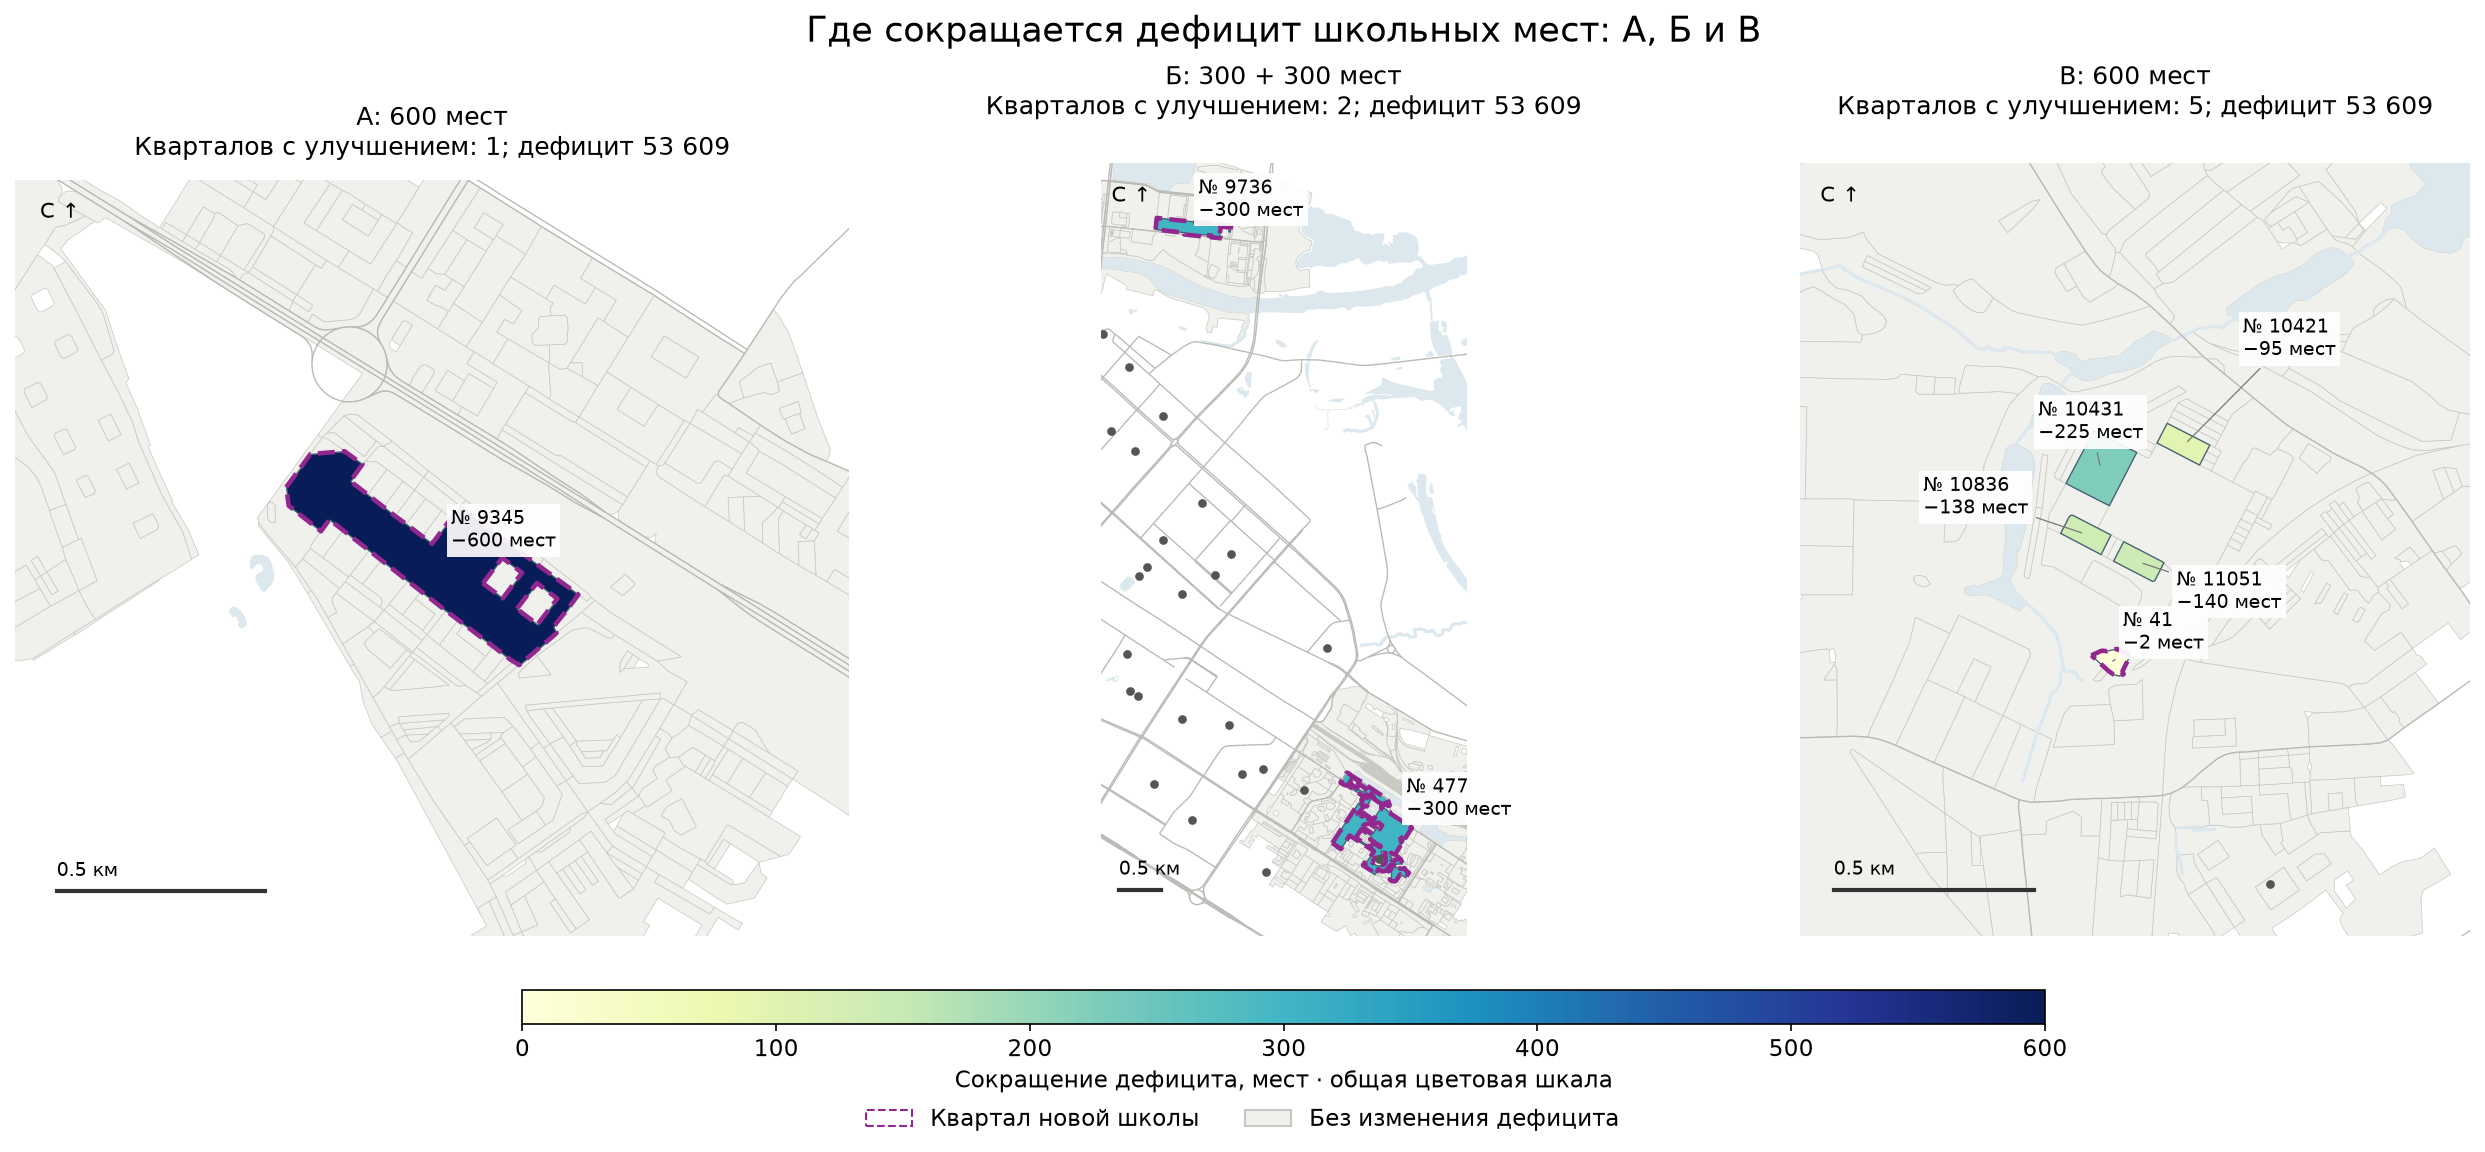

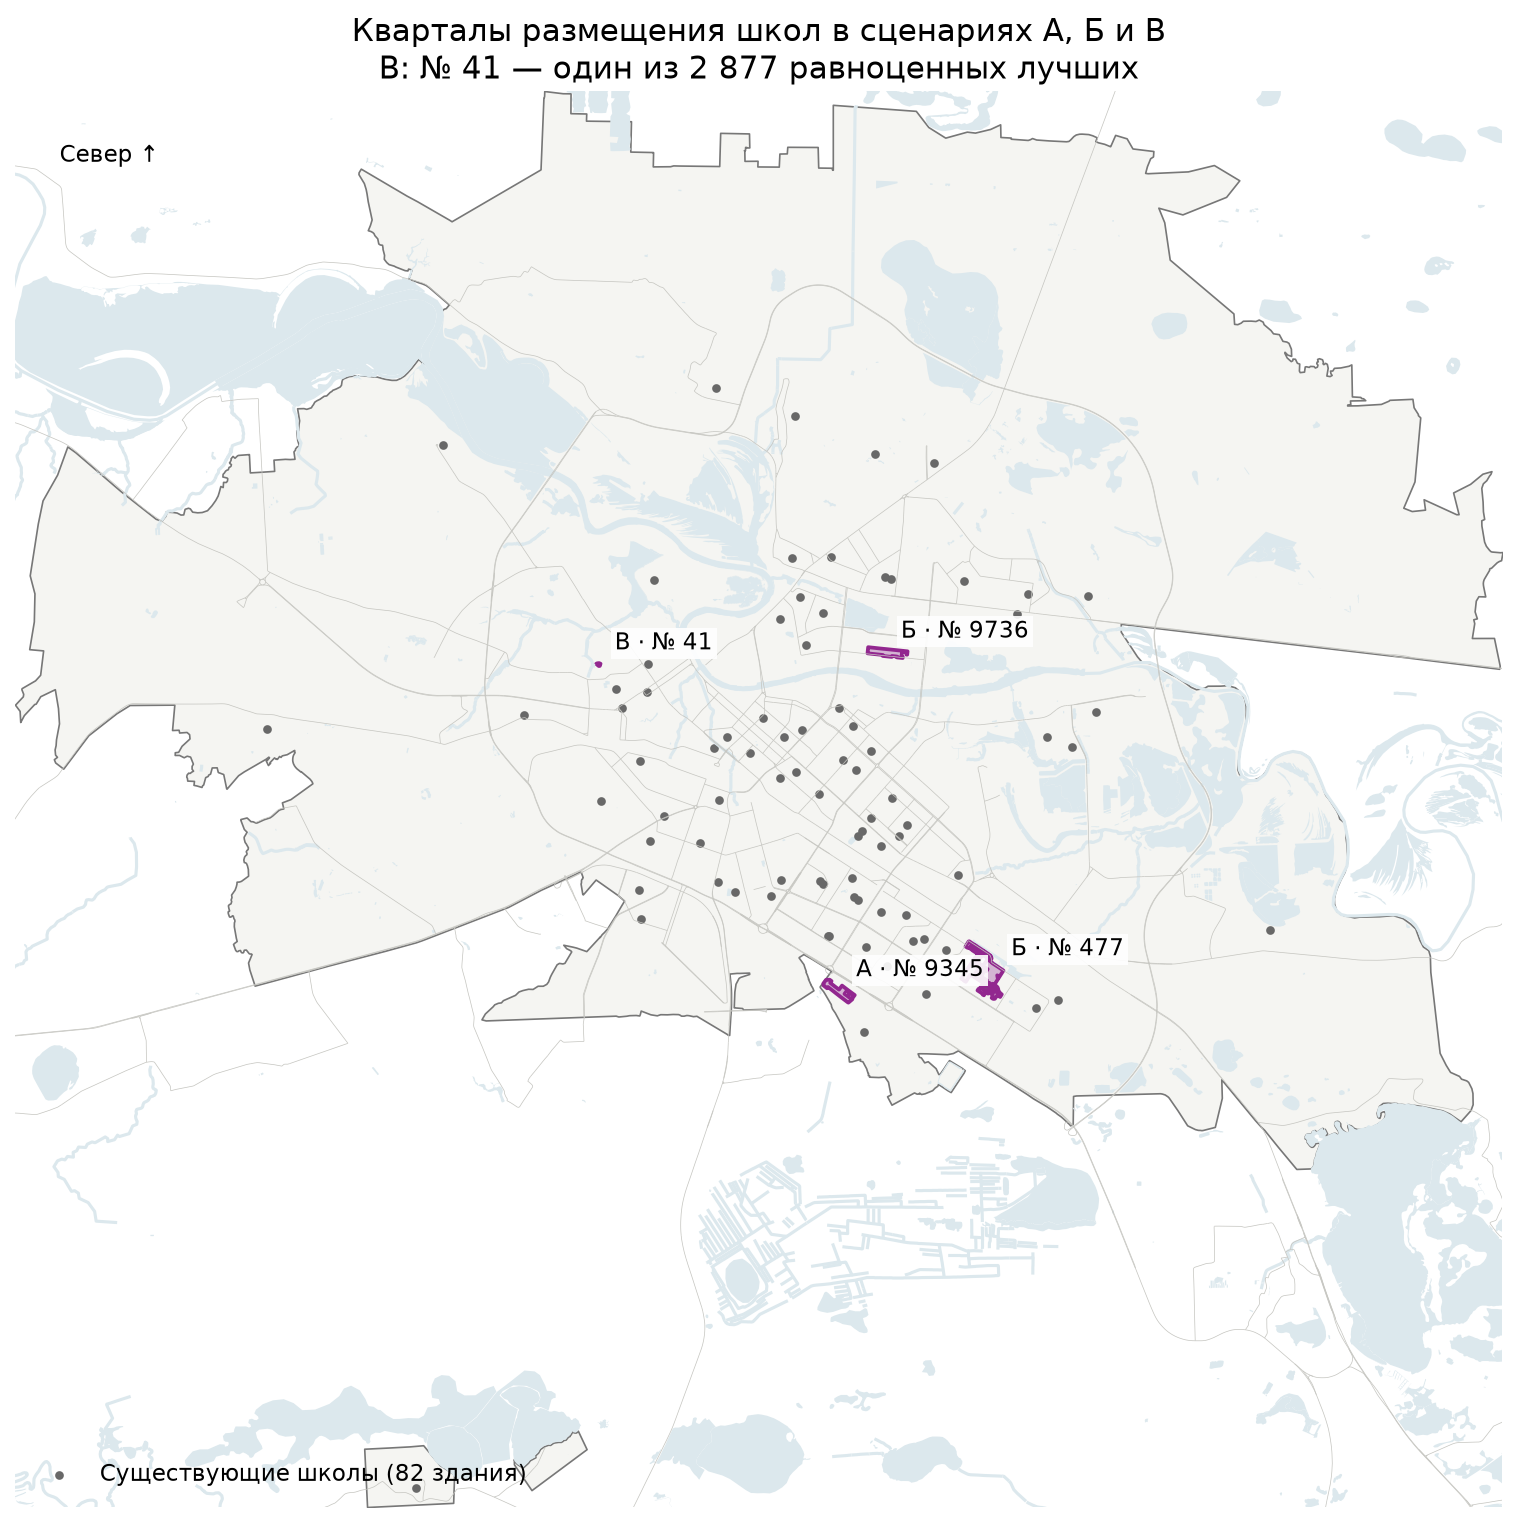

,Квартал,Дефицит,Сокращение,Ошибка,"Время варианта, с"
0,41,53609.0,600.0,NaN,0.340545
1,42,53609.0,600.0,NaN,0.426483
2,43,53609.0,600.0,NaN,0.321164
3,44,53609.0,600.0,NaN,0.348286
4,45,53609.0,600.0,NaN,0.390322
5,51,53609.0,600.0,NaN,0.363989
6,56,53609.0,600.0,NaN,0.353188
7,57,53609.0,600.0,NaN,0.354296
8,59,53609.0,600.0,NaN,0.385857
9,60,53609.0,600.0,NaN,0.337991


Это первые 15 из 2877 равных лучших. Полный список: equal-best.csv.
Полный рейтинг всех кварталов: ranking-all-12805.csv.


In [2]:
display(Image(filename=str(DATA/"scenario-changes.png")))
display(Image(filename=str(DATA/"scenario-locations.png")))
display(best.head(15).rename(columns={"id":"Квартал","deficit":"Дефицит","reduction":"Сокращение","error":"Ошибка","seconds":"Время варианта, с"}))
print("Это первые 15 из 2877 равных лучших. Полный список: equal-best.csv.")
print("Полный рейтинг всех кварталов: ranking-all-12805.csv.")

## Ограничения и просмотр

Население оценено по жилой площади, часть назначения зданий восстановлена по контексту. Вместимости школ оценочные и разной достоверности. Матрица пешеходная, построенная ранее по локальному OSM; требование прошлой практики о скачанном готовом графе буквально не выполнено. Результаты относятся к принятой модели, а не подтверждённой фактической обеспеченности.

После запуска сервера откройте <http://127.0.0.1:8767/> и выберите сохранённые А/Б/В. Это локальный адрес. Для сдачи нужны репозиторий и отдельно переданный архив данных. Полный итоговый текст: `state/experiment-results/EXPERIMENT_REPORT.md`.